# Analisis Risiko Pengadaan Pemerintah Indonesia
**Final Project Data Analyst Bootcamp · Fatwa Ferdiansyah**

**Pertanyaan bisnis:** instansi mana yang skor risiko pengadaannya lebih tinggi daripada yang seharusnya, setelah jenis belanja dan tahunnya diperhitungkan?

**Data:** Government Transparency Institute, berkas `ID_data_202402_gti.csv` (10,79 GB, 187 kolom, 5.453.095 baris). Direduksi dengan skrip `01_reduksi.py` menjadi `kontrak_menang.csv.gz`, `statistik_paket.csv`, dan `statistik_penyedia.csv`.

**Alur notebook:**
1. Eksplorasi data (Blok A, B, C)
2. Pembersihan data
3. Menyusun indikator risiko dan pola musiman
4. Validasi indikator
5. Membandingkan instansi secara setara (standardisasi tidak langsung)
6. Uji ketahanan hasil
7. Temuan dan segmentasi instansi pembeli
8. Ekspor file untuk dasbor

**Cara menjalankan:** unggah tiga berkas hasil reduksi ke Colab, lalu jalankan sel dari atas ke bawah.


### **Eksploratori Data Analysis**

# Blok A. Ukuran, kekosongan, baris kembar, cakupan tahun

In [1]:
# Baca Berkas dan lihat ukuran

import pandas as pd, numpy as np
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

TEKS = {"tender_id": str, "lot_id": str, "bid_id": str, "cpv_code": str,
        "tender_maincpv": str, "buyer_masterid": str, "bidder_masterid": str,
        "bidder_id": str, "tender_year": str}

kontrak = pd.read_csv("kontrak_menang.csv.gz", compression="gzip",
                      dtype=TEKS, low_memory=False)

print("baris :", f"{len(kontrak):,}")
print("kolom :", kontrak.shape[1])
print("memori:", round(kontrak.memory_usage(deep=True).sum()/1e9, 2), "GB")


baris : 1,370,893
kolom : 54
memori: 3.06 GB


In [2]:
# Periksa baris kembar

print("bid_id unik      :", f"{kontrak['bid_id'].nunique():,}")
print("selisih (kembar) :", f"{len(kontrak) - kontrak['bid_id'].nunique():,}")

kembar = kontrak[kontrak.duplicated("bid_id", keep=False)]
print("jumlah tender_id berbeda per bid_id kembar:",
      kembar.groupby("bid_id")["tender_id"].nunique().value_counts().sort_index().to_dict())

bid_id unik      : 1,303,372
selisih (kembar) : 67,521
jumlah tender_id berbeda per bid_id kembar: {1: 27, 2: 67486, 3: 1}


**Keputusan:**
buang baris kembar berdasarkan bid_id, bukan tender_id. Yang dipertahankan adalah baris pertama setelah diurutkan menurut tender_id, supaya hasilnya sama setiap kali dijalankan

In [3]:
k = kontrak.sort_values("tender_id").drop_duplicates("bid_id", keep="first")
print("baris setelah buang kembar:", f"{len(k):,}")

baris setelah buang kembar: 1,303,372


In [4]:
# Periksa kekosongan kolom kunci

kunci = ["tender_year","buyer_name","bidder_name","bid_price_local_currency",
         "tender_estimatedprice_local_currency","savings","cpv_code","lot_bidscount",
         "tender_recordedbidscount","tender_proceduretype","tender_supplytype",
         "tender_selectionmethod","INTEGRITY_SINGLE_BID","INTEGRITY_PROCEDURE_TYPE",
         "INTEGRITY_ADVERTISEMENT_PERIOD","INTEGRITY_DECISION_PERIOD",
         "INTEGRITY_BUYER_CONCENTRATION","buyer_masterid","buyer_county_here",
         "buyer_city_here","local","local_province"]

tab = pd.DataFrame({"terisi": k[kunci].notna().sum()})
tab["persen_kosong"] = (100*(1 - tab["terisi"]/len(k))).round(2)
print(tab.sort_values("persen_kosong", ascending=False).to_string())


                                       terisi  persen_kosong
tender_selectionmethod                 147131          88.71
INTEGRITY_BUYER_CONCENTRATION          676153          48.12
buyer_masterid                         716483          45.03
cpv_code                               962140          26.18
local                                 1229362           5.68
local_province                        1233015           5.40
tender_supplytype                     1270420           2.53
buyer_city_here                       1273236           2.31
buyer_county_here                     1277013           2.02
INTEGRITY_PROCEDURE_TYPE              1297437           0.46
tender_proceduretype                  1297445           0.45
bid_price_local_currency              1297586           0.44
INTEGRITY_ADVERTISEMENT_PERIOD        1300159           0.25
tender_estimatedprice_local_currency  1302635           0.06
lot_bidscount                         1303235           0.01
INTEGRITY_SINGLE_BID    

**Keputusan:**


1.	tender_selectionmethod hanya terisi 11,29 persen. Kolom ini tidak dipakai untuk apa pun.
2.	INTEGRITY_BUYER_CONCENTRATION hanya terisi 51,88 persen. Indikator ini dibuang.
3.	buyer_masterid hanya terisi 54,97 persen. Identitas instansi diturunkan dari buyer_name yang terisi 100 persen.
4.	cpv_code kosong pada 26,18 persen baris. Kolom ini wajib dipakai sebagai pembanding pasar. Konsekuensinya sebagian kontrak tidak dapat masuk ke tahap pembandingan. Ini dicatat sebagai batasan, bukan ditutupi.
5.	local dan local_province kosong sekitar 5,5 persen. Keduanya dipakai sebagai keterangan saja, bukan sebagai indikator.
6.	Empat kolom bahan indikator, yaitu lot_bidscount, INTEGRITY_PROCEDURE_TYPE, INTEGRITY_ADVERTISEMENT_PERIOD, dan INTEGRITY_DECISION_PERIOD, terisi di atas 99,5 persen dan layak dipakai.


In [5]:
# Cek tidak ada kolom yang kosong total

kosong_total = [c for c in kontrak.columns if kontrak[c].notna().sum() == 0]
print("jumlah kolom :", kontrak.shape[1])
print("kosong total :", len(kosong_total), kosong_total)

jumlah kolom : 54
kosong total : 0 []


In [6]:
# Cek Cakupan Tahun

k["tahun"] = pd.to_numeric(k["tender_year"].astype(str).str[:4], errors="coerce")
print(k["tahun"].value_counts().sort_index().to_string())

tahun
2008.0        20
2009.0      1363
2010.0      5604
2011.0     20324
2012.0     78852
2013.0    111424
2014.0    125346
2015.0    144613
2016.0    145416
2017.0    124010
2018.0    114415
2019.0    112453
2020.0     73084
2021.0     94849
2022.0     82398
2023.0     66263
2024.0      2937


**Keputusan:** tahun 2008 sampai 2011 dan tahun 2024 dikeluarkan dari analisis utama karena jumlahnya terlalu kecil untuk membentuk pembanding yang stabil. Rentang yang dipakai adalah 2013 sampai 2023.

# Blok B. Keganjilan yang mengubah analisis

In [7]:
# Ada dua kolom jumlah penawar yang isinya berbeda jauh

for c in ["lot_bidscount", "tender_recordedbidscount",
          "bid_price_local_currency", "tender_estimatedprice_local_currency"]:
    k[c] = pd.to_numeric(k[c], errors="coerce")

print("lot_bidscount            median", k["lot_bidscount"].median(),
      "rata", round(k["lot_bidscount"].mean(),1))
print("tender_recordedbidscount median", k["tender_recordedbidscount"].median(),
      "rata", round(k["tender_recordedbidscount"].mean(),1))
print("korelasi                       :",
      round(k["lot_bidscount"].corr(k["tender_recordedbidscount"]), 3))
print("lot_bidscount == 1            :", f'{(k["lot_bidscount"]==1).sum():,}',
      f'({100*(k["lot_bidscount"]==1).mean():.2f}%)')
print("recordedbidscount == 1        :", f'{(k["tender_recordedbidscount"]==1).sum():,}',
      f'({100*(k["tender_recordedbidscount"]==1).mean():.2f}%)')


lot_bidscount            median 21.0 rata 28.5
tender_recordedbidscount median 2.0 rata 3.5
korelasi                       : 0.304
lot_bidscount == 1            : 4,739 (0.36%)
recordedbidscount == 1        : 513,211 (39.38%)


Interpretasi:

1.	Kedua kolom itu tidak mengukur hal yang sama. Korelasinya hanya 0,304.
2.	lot_bidscount bernilai median 21. Angka ini terlalu besar untuk jumlah penawaran yang benar-benar masuk. Angka ini adalah jumlah peserta yang mendaftar atau mengunduh dokumen di SPSE.
3.	tender_recordedbidscount bernilai median 2. Angka ini adalah jumlah penawaran yang benar-benar tercatat.
4.	Kalau indikator satu penawar dihitung dari lot_bidscount, hasilnya 0,36 persen. Kalau dihitung dari jumlah penawaran yang tercatat, hasilnya sekitar 39 persen.

Selisih ini bukan hal kecil. Indikator satu penawar adalah indikator utama dalam seluruh literatur risiko pengadaan. Salah memilih kolom membuat indikator utama itu lumpuh.


In [8]:
# kolom indikator resmi mengikuti kolom yang salah

isb = pd.to_numeric(k["INTEGRITY_SINGLE_BID"], errors="coerce")
print(pd.crosstab(k["lot_bidscount"]==1, isb, dropna=False).to_string())

INTEGRITY_SINGLE_BID   0.0      1.0  NaN
lot_bidscount                           
False                    0  1298496  137
True                  4739        0    0


**Keputusan**: indikator satu penawar dihitung sendiri, tidak memakai kolom INTEGRITY_SINGLE_BID. Dasar perhitungannya adalah jumlah baris penawaran per paket yang dihitung dari berkas mentah dan disimpan dalam statistik_paket.csv sebagai kolom n_baris. Kolom itu dipilih, bukan tender_recordedbidscount, karena n_baris berada pada tingkat paket sedangkan tender_recordedbidscount berada pada tingkat tender. Indikator risiko bekerja pada tingkat paket.

In [9]:
# jenis prosedur hanya terekam pada sebagian tahun

t = pd.crosstab(k["tahun"], k["tender_proceduretype"])
t["% non-terbuka"] = (100*(t.sum(axis=1) - t.get("OPEN", 0))/t.sum(axis=1)).round(1)
print(t[t.sum(axis=1) > 100].to_string())

tender_proceduretype  DESIGN_CONTEST    OPEN  OTHER  OUTRIGHT_AWARD  RESTRICTED  % non-terbuka
tahun                                                                                         
2009.0                             0    1363      0               0           0            0.0
2010.0                             0    5604      0               0           0            0.0
2011.0                             0   19978      0               0         346            1.7
2012.0                             0   74538      0             450        3864            5.5
2013.0                             0   55422      1           46378        9623           50.3
2014.0                             0   52647      0           60641       12058           58.0
2015.0                             0   60338      0           69034       15241           58.3
2016.0                             0   56875      1           71517       17023           60.9
2017.0                             0   49219      

**Keputusan**:

1.	Indikator jenis prosedur tidak dipakai dalam skor risiko utama, karena tidak sebanding antar tahun.
2.	Analisis dipecah menjadi dua periode: 2013 sampai 2018 dan 2019 sampai 2023. Kedua periode dianalisis terpisah dengan skor yang sama, lalu hasilnya dibandingkan.
3.	Pemecahan ini berubah dari kelemahan menjadi kekuatan. Dua periode yang terpisah memberi satu kesempatan uji yang tidak ada kalau seluruh tahun digabung, yaitu menguji apakah peringkat instansi bertahan.
4.	Analisis penunjukan langsung tetap dilakukan, tetapi dibatasi tegas pada 2013 sampai 2018 dan dilaporkan terpisah.


In [10]:
# Cek Kode CPV

cp = k["cpv_code"].dropna()
print(cp.str.len().value_counts().sort_index().to_string())

print("\nawalan dua digit menurut panjang:")
for L in sorted(cp.str.len().unique()):
    s = cp[cp.str.len() == L]
    print(" panjang", L, "->", dict(s.str[:2].value_counts().head(6).astype(int)))

print("\ndiawali angka nol:", f"{cp.str.startswith('0').sum():,}",
      f"({100*cp.str.startswith('0').mean():.1f}% dari kode yang terisi)")


cpv_code
8     627681
9     264551
10     69908

awalan dua digit menurut panjang:
 panjang 8 -> {'45': np.int64(379805), '71': np.int64(27792), '30': np.int64(22820), '34': np.int64(22183), '33': np.int64(16919), '44': np.int64(15148)}
 panjang 9 -> {'45': np.int64(182575), '04': np.int64(44939), '71': np.int64(9069), '07': np.int64(7358), '09': np.int64(5092), '03': np.int64(4994)}
 panjang 10 -> {'04': np.int64(20537), '03': np.int64(16706), '08': np.int64(14754), '07': np.int64(9846), '09': np.int64(4070), '06': np.int64(1806)}

diawali angka nol: 133,489 (13.9% dari kode yang terisi)


Interpretasi:

1.	Hanya 627.681 kode yang panjangnya 8 digit sesuai standar.
2.	Kode sepanjang 9 digit adalah kode 8 digit yang diberi satu digit pemeriksa di belakang, atau kode 8 digit yang diberi angka nol di depan.
3.	Kode sepanjang 10 digit seluruhnya diawali angka nol dan diakhiri digit pemeriksa.
4.	Awalan 04, 06, 07, dan 08 bukan divisi CPV yang sah. Kemunculannya membuktikan adanya angka nol tambahan di depan.


Akibat kalau tidak diperbaiki: mengambil dua karakter pertama menempatkan pekerjaan konstruksi yang berkode 045232000 ke kelompok 04, padahal seharusnya 45. Kelompok pasar yang salah membuat pembanding menjadi salah.

In [11]:
DIVISI = {"03","09","14","15","16","18","19","22","24","30","31","32","33","34","35",
          "37","38","39","41","42","43","44","45","48","50","51","55","60","63","64",
          "65","66","70","71","72","73","75","76","77","79","80","85","90","92","98"}

def divisi(kode):
    if not isinstance(kode, str) or kode == "":
        return np.nan
    p = len(kode)
    if p == 10 and kode.startswith("0"):
        d = kode[1:3]                                   # nol di depan, buang
    elif p == 9 and kode.startswith("0") and kode[:2] not in ("03", "09"):
        d = kode[1:3]                                   # nol di depan, buang
    else:
        d = kode[:2]                                    # ambil apa adanya
    return d if d in DIVISI else np.nan

k["pasar_lama"] = cp.str[:2].reindex(k.index)
k["pasar"] = k["cpv_code"].map(divisi)

pindah = k["pasar"].notna() & k["pasar_lama"].notna() & (k["pasar"] != k["pasar_lama"])
print("kode yang berpindah kelompok setelah perbaikan:", f"{pindah.sum():,}")
print("kelompok pasar terisi:", f'{k["pasar"].notna().sum():,}',
      f'({100*k["pasar"].notna().mean():.1f}%)')
print(k["pasar"].value_counts().head(8).to_string())


kode yang berpindah kelompok setelah perbaikan: 123,403
kelompok pasar terisi: 961,621 (73.8%)
pasar
45    619528
71     46229
34     27014
30     24576
85     23136
33     21939
44     19474
15     15172


In [12]:
# Sebaran rasio harga terhadap HPS

k["rasio"] = k["bid_price_local_currency"]/k["tender_estimatedprice_local_currency"]
r = k["rasio"].replace([np.inf, -np.inf], np.nan).dropna()

print("terhitung:", f"{len(r):,}")
print("persentil:", {p: round(r.quantile(p), 4)
                     for p in [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]})

LABEL = ["<1%","1-10%","10-50%","50-80%","80-100%","100-120%","120-200%",">200%"]
BATAS = [-np.inf, 0.01, 0.1, 0.5, 0.8, 1.0, 1.2, 2, np.inf]
band = pd.cut(r, BATAS, labels=LABEL)
bb = pd.DataFrame({"jumlah": band.value_counts().sort_index()})
bb["persen"] = (100*bb["jumlah"]/len(r)).round(2)
bb["HPS_Rp_T"] = (k.loc[r.index]
                   .groupby(band, observed=False)["tender_estimatedprice_local_currency"]
                   .sum().div(1e12).round(1))
print(bb.to_string())


terhitung: 1,296,980
persentil: {0.001: np.float64(0.3214), 0.01: np.float64(0.6623), 0.05: np.float64(0.7839), 0.25: np.float64(0.9157), 0.5: np.float64(0.9708), 0.75: np.float64(0.9898), 0.95: np.float64(0.998), 0.99: np.float64(0.9999), 0.999: np.float64(1.0811)}
           jumlah  persen  HPS_Rp_T
rasio                              
<1%           143    0.01      12.3
1-10%         403    0.03       5.8
10-50%       2505    0.19      17.0
50-80%      90972    7.01     219.9
80-100%   1198834   92.43    2834.5
100-120%     3331    0.26       7.7
120-200%      312    0.02       0.5
>200%         480    0.04       0.7


Keputusan: untuk seluruh analisis harga, dipakai hanya kontrak dengan rasio antara 0,10 dan 1,20. Batas ini dipilih karena:

1.	Batas bawah 0,10 membuang kontrak yang jelas salah satuan tanpa membuang kontrak yang memang murah.

2.	Batas atas 1,20 memberi ruang bagi kontrak dengan negosiasi sah yang sedikit melewati HPS, tetapi tetap membuang kesalahan pencatatan besar.

3.	Baris yang keluar dari rentang ini tidak dihapus dari tabel. Baris itu hanya ditandai lewat kolom harga_wajar, supaya indikator risiko tetap dapat dihitung untuk baris tersebut.
Jumlah yang terpengaruh: 7.691 kontrak dari 1.301.381, atau 0,6 persen.

# Blok C. Nama Instansi

In [13]:
# Cek Keragaman Penulisan Nama Instansi

k["induk_mentah"] = (k["buyer_name"].astype(str)
                       .str.split(" -- ", n=1).str[0].str.strip().str.upper())

print("nama buyer_name unik :", f'{k["buyer_name"].nunique():,}')
print("induk mentah unik    :", f'{k["induk_mentah"].nunique():,}')
print(k.loc[k["induk_mentah"].str.contains("MUNA", na=False), "induk_mentah"]
        .value_counts().head(8).to_string())


nama buyer_name unik : 57,684
induk mentah unik    : 5,537
induk_mentah
KAB. MUNA                                             1131
PEMERINTAH DAERAH KABUPATEN MUNA BARAT                 830
ULP KAB.MUNA                                           740
PEMDA KAB. MUNA                                        220
LPSE KAB. MUNA                                          88
DINAS PEKERJAAN UMUM KABUPATEN MUNA                     37
DINAS TENAGA KERJA DAN TRANSMIGRASI KABUPATEN MUNA      12
KOMISI PEMILIHAN UMUM KABUPATEN MUNA                     3


# Pembersihan Data

In [14]:
import pandas as pd, numpy as np, re, json

TEKS = {"tender_id": str, "lot_id": str, "bid_id": str, "cpv_code": str,
        "tender_maincpv": str, "buyer_masterid": str, "bidder_masterid": str,
        "bidder_id": str, "tender_year": str}

kontrak = pd.read_csv("kontrak_menang.csv.gz", compression="gzip",
                      dtype=TEKS, low_memory=False)
paket = pd.read_csv("statistik_paket.csv", dtype={"lot_id": str})

catatan = {}
catatan["baris awal"] = len(kontrak)

# 1. buang baris kembar berdasarkan bid_id
kontrak = kontrak.sort_values("tender_id").drop_duplicates("bid_id", keep="first")
catatan["baris kembar dibuang"] = catatan["baris awal"] - len(kontrak)

# 2. gabungkan statistik paket, pastikan tidak menggandakan baris
paket = paket.drop_duplicates("lot_id", keep="first")
df = kontrak.merge(paket, on="lot_id", how="left")
assert len(df) == len(kontrak), "penggabungan menggandakan baris, periksa lot_id"
catatan["baris setelah gabung"] = len(df)
del kontrak, paket

# 3. ubah kolom angka menjadi numerik
ANGKA = ["bid_price_local_currency","tender_estimatedprice_local_currency","savings",
         "advertisement_period","decision_period","award_period_length","lot_bidscount",
         "tender_recordedbidscount","tender_lotscount","n_baris","n_penyedia_bernama",
         "total_harga","total_kuadrat","harga_min","harga_max","harga_menang","hps",
         "INTEGRITY_SINGLE_BID","INTEGRITY_PROCEDURE_TYPE","INTEGRITY_ADVERTISEMENT_PERIOD",
         "INTEGRITY_DECISION_PERIOD","local","local_province"]
for c in ANGKA:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["tahun"] = pd.to_numeric(df["tender_year"].astype(str).str[:4],
                            errors="coerce").astype("Int64")

# 4. kelompok pasar dari kode CPV
DIVISI = {"03","09","14","15","16","18","19","22","24","30","31","32","33","34","35",
          "37","38","39","41","42","43","44","45","48","50","51","55","60","63","64",
          "65","66","70","71","72","73","75","76","77","79","80","85","90","92","98"}

def divisi(kode):
    if not isinstance(kode, str) or kode == "":
        return np.nan
    p = len(kode)
    if p == 10 and kode.startswith("0"):
        d = kode[1:3]
    elif p == 9 and kode.startswith("0") and kode[:2] not in ("03", "09"):
        d = kode[1:3]
    else:
        d = kode[:2]
    return d if d in DIVISI else np.nan

df["pasar"] = df["cpv_code"].map(divisi)
catatan["kontrak dengan kode pasar"] = int(df["pasar"].notna().sum())

# 5. seragamkan nama instansi
PUSAT = re.compile(
    r"^(KEMENTERIAN|KEMENTRIAN|MAHKAMAH|KEJAKSAAN|KEPOLISIAN|POLDA|POLRES|MABES|MARKAS"
    r"|TNI|KODAM|KOREM|LANTAMAL|LANUD|BADAN|LEMBAGA|ARSIP|PERPUSTAKAAN|UNIVERSITAS"
    r"|INSTITUT|POLITEKNIK|SEKOLAH|KOMISI|DEWAN|OMBUDSMAN"
    r"|SEKRETARIAT (NEGARA|KABINET|JENDERAL)|KANTOR (WILAYAH|PUSAT)|KANWIL"
    r"|DIREKTORAT|DITJEN|PUSAT|RSUP|BALAI|OTORITAS|ISTANA)\b")

BUANG = re.compile(
    r"^(LPSE|ULP|UKPBJ|UNIT LAYANAN PENGADAAN|LAYANAN PENGADAAN SECARA ELEKTRONIK"
    r"|LAYANAN PENGADAAN|BAGIAN LAYANAN PENGADAAN|BARANG DAN JASA|POKJA|SETDA"
    r"|SEKRETARIAT DAERAH|PEMERINTAH DAERAH|PEMERINTAH|PEMDA|AGENCY)\b\s*")

WIL = re.compile(r"\b(KAB\.|KOTA|PROV\.)\s+[A-Z]")

def inti(t):
    t = re.sub(r"[^A-Z0-9\. ]+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"\s+(19|20)\d{2}$", "", t)
    t = re.sub(r"\s+AGENCY$", "", t)
    t = re.sub(r"\b(PEMKAB|PEMKOT|PEMPROV|KAB|KOTA|PROV|PROP)\.(?=[A-Z])", r"\1. ", t)
    t = re.sub(r"\bPEMKAB\b\.?|\bKABUPATEN\b|\bKAB\b\.?", "KAB.", t)
    t = re.sub(r"\bPEMKOT\b\.?|\bKOTAMADYA\b|\bKOTAMADIA\b|\bKOTA\b", "KOTA", t)
    t = re.sub(r"\bPEMPROV\b\.?|\bPROVINSI\b|\bPROPINSI\b"
               r"|\bPROV\b\.?|\bPROP\b\.?", "PROV.", t)
    t = re.sub(r"\s+", " ", t).strip()
    pusat = bool(PUSAT.match(t))
    for _ in range(4):
        t2 = BUANG.sub("", t)
        if t2 == t:
            break
        t = t2
    t = re.sub(r"\s+", " ", t).strip()
    if not pusat:
        m = WIL.search(t)
        if m:
            t = t[m.start():].strip()
    return t

def rapikan(nama):
    bagian = str(nama).upper().split(" -- ")
    hasil = inti(bagian[0])
    if not hasil and len(bagian) > 1:
        hasil = inti(bagian[1])
    return hasil

unik = pd.DataFrame({"buyer_name": df["buyer_name"].dropna().unique()})
unik["induk"] = unik["buyer_name"].map(rapikan)
unik["kunci"] = unik["induk"].str.replace(r"[\. ]", "", regex=True)
unik = unik.join(df.groupby("buyer_name").size().rename("c"), on="buyer_name")

pilih = (unik.groupby(["kunci", "induk"])["c"].sum().reset_index()
              .sort_values("c", ascending=False)
              .drop_duplicates("kunci").set_index("kunci")["induk"])
unik["induk"] = unik["kunci"].map(pilih)

kanon = set(unik["induk"].unique())
peta, ambigu = {}, set()
for n in kanon:
    if not n or n.startswith(("KAB. ", "KOTA ", "PROV. ")):
        continue
    cocok = [p + n for p in ("KAB. ", "KOTA ", "PROV. ") if p + n in kanon]
    if len(cocok) == 1:
        peta[n] = cocok[0]
    elif len(cocok) > 1:
        ambigu.add(n)
unik["induk"] = unik["induk"].replace(peta)

df = df.merge(unik[["buyer_name", "induk"]], on="buyer_name", how="left")
df["induk_ambigu"] = df["induk"].isin(ambigu)
catatan["nama buyer unik"] = int(len(unik))
catatan["instansi induk unik"] = int(df["induk"].nunique())
catatan["digabung tahap nama telanjang"] = len(peta)

sebelum = len(df)
df = df[df["induk"].notna() & (df["induk"] != "")]
catatan["gugur: instansi tak terbaca"] = sebelum - len(df)

# 6. indikator risiko
df["satu_penawar"] = (df["n_baris"] == 1).astype(int)
df["r_satu"]  = df["satu_penawar"] * 100
df["r_iklan"] = (1 - df["INTEGRITY_ADVERTISEMENT_PERIOD"]) * 100
df["r_putus"] = (1 - df["INTEGRITY_DECISION_PERIOD"]) * 100
df["r_proc"]  = (1 - df["INTEGRITY_PROCEDURE_TYPE"]) * 100
df["cri"] = df[["r_satu", "r_iklan", "r_putus"]].mean(axis=1, skipna=False)
catatan["kontrak dengan CRI"] = int(df["cri"].notna().sum())

# 7. rasio harga dan penandaan
df["rasio_hps"] = df["bid_price_local_currency"] / df["tender_estimatedprice_local_currency"]
df["harga_wajar"] = df["rasio_hps"].between(0.10, 1.20)
catatan["harga wajar"] = int(df["harga_wajar"].sum())
catatan["harga tidak wajar atau kosong"] = int(len(df) - df["harga_wajar"].sum())

df["siap"] = df["cri"].notna() & df["pasar"].notna() & df["tahun"].notna()
catatan["siap untuk perbandingan"] = int(df["siap"].sum())
catatan["baris akhir"] = len(df)

print(json.dumps(catatan, indent=1))

try:
    df.to_parquet("analisis_siap.parquet", index=False)
except ImportError:
    df.to_csv("analisis_siap.csv.gz", index=False, compression="gzip")


{
 "baris awal": 1370893,
 "baris kembar dibuang": 67521,
 "baris setelah gabung": 1303372,
 "kontrak dengan kode pasar": 961621,
 "nama buyer unik": 57684,
 "instansi induk unik": 3741,
 "digabung tahap nama telanjang": 52,
 "gugur: instansi tak terbaca": 1991,
 "kontrak dengan CRI": 1298179,
 "harga wajar": 1293690,
 "harga tidak wajar atau kosong": 7691,
 "siap untuk perbandingan": 957460,
 "baris akhir": 1301381
}


In [15]:
# setelah kolom induk dibuat, pastikan nama yang mirip benar-benar tergabung
muna = df.loc[df["induk"].str.contains("MUNA", na=False), "induk"]
print(muna.value_counts().to_string())
bogor = df.loc[df["induk"].str.contains("BOGOR", na=False), "induk"]
print(bogor.value_counts().head(5).to_string())

induk
KAB. MUNA                          2229
KAB. MUNA BARAT                     830
KOMISI PEMILIHAN UMUM KAB. MUNA       3
induk
KAB. BOGOR                              9099
KOTA BOGOR                              2442
ISTANA KEPRESIDENAN BOGOR                 28
POLITEKNIK AKA BOGOR                      22
SEKOLAH MENENGAH KEJURUAN SMAK BOGOR      14


# Menyusun Indikator Risiko

In [16]:
# Sebaran Skor

w = df[df["harga_wajar"] & df["cri"].notna() & df["tahun"].between(2013, 2023)]
t = w.groupby(w["cri"].round(1)).agg(kontrak=("cri","size"),
                                     median_rasio=("rasio_hps","median"))
t["persen"] = (100*t["kontrak"]/len(w)).round(1)
print(t[["kontrak","persen","median_rasio"]].round(4).to_string())


       kontrak  persen  median_rasio
cri                                 
0.0     122957    10.4        0.9435
16.7    277185    23.4        0.9473
33.3    240126    20.3        0.9681
50.0    217396    18.4        0.9764
66.7    179162    15.2        0.9842
83.3    101415     8.6        0.9878
100.0    44020     3.7        0.9895


Cakupan tabel ini adalah 1.182.261 kontrak, yaitu kontrak tahun 2013 sampai 2023 yang punya skor risiko dan lolos saringan harga wajar

In [17]:
# Pola musiman: risiko naik menjelang akhir tahun anggaran

if "tender_publications_firstcallfortenderdate" not in df.columns:
    tgl = pd.read_parquet("analisis_siap.parquet",
                          columns=["tender_publications_firstcallfortenderdate"])
    df["tender_publications_firstcallfortenderdate"] = tgl.iloc[:, 0].reindex(df.index)

m = df[df["cri"].notna() & df["tahun"].between(2013, 2023)].copy()
m["bulan"] = pd.to_datetime(m["tender_publications_firstcallfortenderdate"],
                            errors="coerce").dt.month

bln = m.groupby("bulan").agg(
        kontrak=("cri", "size"),
        skor_rata=("cri", "mean"),
        sepi_penawar=("r_satu",  lambda s: 100*(s == 100).mean()),
        iklan_pendek=("r_iklan", lambda s: 100*(s == 100).mean()),
        putusan_tidak_wajar=("r_putus", lambda s: 100*(s == 100).mean()))
bln["persen_kontrak"] = 100*bln["kontrak"]/bln["kontrak"].sum()
print("total kontrak:", f"{len(m):,}")
print(bln.round(1).to_string())

puncak = m.groupby(["tahun", "bulan"])["cri"].mean().unstack().idxmax(axis=1)
print("\nbulan dengan skor tertinggi tiap tahun:",
      {int(k): int(v) for k, v in puncak.items()})


total kontrak: 1,189,529
       kontrak  skor_rata  sepi_penawar  iklan_pendek  putusan_tidak_wajar  persen_kontrak
bulan                                                                                     
1        41013       33.8          28.9          16.1                 17.7             3.4
2        64509       34.0          29.8          16.7                 15.0             5.4
3       106014       34.5          33.5          16.5                 12.8             8.9
4       128915       35.4          36.5          17.6                 10.9            10.8
5       151671       36.8          38.2          18.9                 11.1            12.8
6       175535       41.7          39.2          27.6                 14.4            14.8
7       144838       42.2          38.8          29.1                 16.8            12.2
8       124860       45.3          41.8          30.1                 17.4            10.5
9        96399       48.2          42.2          31.9            

Temuan: skor risiko rata-rata naik dari 33,8 pada Januari menjadi 53,2 pada Oktober, dan puncaknya jatuh di Oktober atau November pada 11 dari 11 tahun. Porsi paket dengan masa iklan pendek naik dari 16 persen menjadi 37 persen. Volume kontrak justru memuncak di Juni, jadi kenaikan risiko bukan karena kontraknya banyak.

Dugaan: paket yang diumumkan mendekati akhir tahun anggaran dikejar tenggat, sehingga masa iklan dipersingkat dan penawar lebih sedikit.

Tindak lanjut: paket yang diumumkan September sampai November diberi pengawasan tambahan, dan lelang dini didorong.

# Validasi Indikator

In [18]:
# Uji tiap indikator secara terpisah

for kol, nama in [("r_satu","satu penawar"), ("r_iklan","masa iklan"),
                  ("r_putus","masa putusan"), ("r_proc","prosedur (2013-2018)")]:
    sub = w if kol != "r_proc" else w[w["tahun"].between(2013, 2018)]
    g = sub.groupby(sub[kol])["rasio_hps"].agg(["size","median"])
    hasil = {int(i): (int(r["size"]), round(r["median"], 4)) for i, r in g.iterrows()}
    print(f"{nama:24s}", hasil)


satu penawar             {0: (732191, np.float64(0.9564)), 100: (450070, np.float64(0.9844))}
masa iklan               {0: (264854, np.float64(0.9621)), 50: (623345, np.float64(0.9702)), 100: (294062, np.float64(0.9805))}
masa putusan             {0: (594101, np.float64(0.9599)), 50: (390461, np.float64(0.9787)), 100: (197699, np.float64(0.9841))}
prosedur (2013-2018)     {0: (398214, np.float64(0.9715)), 100: (356665, np.float64(0.9744))}


Boleh disimpulkan:

1.	Skor risiko berhubungan dengan hasil ekonomi yang secara teori memang diharapkan.
2.	Skor risiko bukan angka acak.

Tidak boleh disimpulkan:

1.	Bahwa kontrak berskor tinggi adalah kontrak korup. Rasio harga yang tinggi juga bisa terjadi karena HPS disusun terlalu ketat atau karena pasarnya memang tipis.
2.	Bahwa selisih 4,95 poin persen adalah kerugian negara. Selisih itu adalah perbedaan rata-rata antar kelompok, bukan hasil audit.

# Membandingkan Instansi Secara Setara

In [19]:
import pandas as pd, numpy as np

KOL = ["bid_id","tender_id","induk","tahun","pasar","cri","r_satu","r_iklan","r_putus",
       "rasio_hps","harga_wajar","bid_price_local_currency",
       "tender_estimatedprice_local_currency","siap"]
df = pd.read_parquet("analisis_siap.parquet", columns=KOL)

d = df[df["siap"]].copy()
d["sel"] = d["tahun"].astype(str) + "-" + d["pasar"]

def oe_instansi(data, minimal=100):
    # rata-rata skor per sel tahun-pasar
    sel_n = (data.groupby("sel")["cri"].agg(["size","sum"])
                 .rename(columns={"size":"n_c","sum":"s_c"}))
    # jumlah dan total skor per instansi di tiap sel
    ic = (data.groupby(["induk","sel"])["cri"].agg(["size","sum"])
              .rename(columns={"size":"n_ic","sum":"s_ic"}).reset_index())
    ic = ic.join(sel_n, on="sel")

    # rata-rata sel TANPA instansi itu sendiri
    sisa_n = ic["n_c"] - ic["n_ic"]
    ic["rata_lain"] = np.where(sisa_n > 0,
                               (ic["s_c"] - ic["s_ic"]) / sisa_n.replace(0, np.nan),
                               np.nan)
    ic["e_ic"] = ic["n_ic"] * ic["rata_lain"]
    ic = ic[ic["e_ic"].notna()]

    agg = ic.groupby("induk").agg(n=("n_ic","sum"), O=("s_ic","sum"), E=("e_ic","sum"))

    # simpangan baku dengan pengelompokan menurut tender
    peta = ic.set_index(["induk","sel"])["rata_lain"]
    data = data.join(peta.rename("harap"), on=["induk","sel"])
    data = data[data["harap"].notna()]
    data["sisa"] = data["cri"] - data["harap"]
    gk = data.groupby(["induk","tender_id"])["sisa"].sum()
    kl = gk.groupby("induk").agg(G="size", SS=lambda s: (s**2).sum())

    out = agg.join(kl)
    out["se"] = np.sqrt(out["SS"] * out["G"] / (out["G"] - 1).clip(lower=1))
    out["oe"] = out["O"] / out["E"]
    out["lo"] = (out["O"] - out["E"] - 1.96*out["se"]) / out["E"] + 1
    out["hi"] = (out["O"] - out["E"] + 1.96*out["se"]) / out["E"] + 1
    out["cri_rata"]  = out["O"] / out["n"]
    out["cri_harap"] = out["E"] / out["n"]
    return out[out["n"] >= minimal].drop(columns=["G","SS","se"]).reset_index()

A = oe_instansi(d[d["tahun"].between(2013, 2018)])
B = oe_instansi(d[d["tahun"].between(2019, 2023)])

for nama, t in [("2013-2018", A), ("2019-2023", B)]:
    print(f"{nama}: {len(t)} instansi | di atas {(t['lo']>1).sum()}"
          f" | di bawah {(t['hi']<1).sum()}"
          f" | tidak berbeda {((t['lo']<=1)&(t['hi']>=1)).sum()}")

M = A.merge(B, on="induk", suffixes=("_A","_B"))
M["gigih"] = (M["lo_A"] > 1) & (M["lo_B"] > 1)
print("hadir dua periode:", len(M),
      "| korelasi peringkat:", round(M["oe_A"].corr(M["oe_B"], method="spearman"), 3),
      "| di atas norma pada keduanya:", int(M["gigih"].sum()))
M.to_csv("oe_instansi.csv", index=False)


2013-2018: 726 instansi | di atas 333 | di bawah 292 | tidak berbeda 101
2019-2023: 551 instansi | di atas 227 | di bawah 256 | tidak berbeda 68
hadir dua periode: 518 | korelasi peringkat: 0.669 | di atas norma pada keduanya: 170


# Uji Ketahanan Hasil

In [20]:
M["gigih"] = (M["lo_A"] > 1) & (M["lo_B"] > 1)

hanya_A = (M["lo_A"] > 1) & ~(M["lo_B"] > 1)
hanya_B = ~(M["lo_A"] > 1) & (M["lo_B"] > 1)

print("instansi yang aktif pada kedua periode :", len(M))
print("korelasi peringkat antar periode       :",
      round(M["oe_A"].corr(M["oe_B"], method="spearman"), 3))
print("di atas norma pada kedua periode       :", int(M["gigih"].sum()))
print("di atas norma hanya pada periode 2013-2018 :", int(hanya_A.sum()))
print("di atas norma hanya pada periode 2019-2023 :", int(hanya_B.sum()))

instansi yang aktif pada kedua periode : 518
korelasi peringkat antar periode       : 0.669
di atas norma pada kedua periode       : 170
di atas norma hanya pada periode 2013-2018 : 87
di atas norma hanya pada periode 2019-2023 : 42


Korelasi 0.669 pada dua kumpulan kontrak yang sepenuhnya berbeda adalah hasil yang kuat

In [21]:
d = df[df["siap"]].copy()
sup = pd.read_parquet("analisis_siap.parquet", columns=["tender_supplytype"])
d["tender_supplytype"] = sup["tender_supplytype"].reindex(d.index)

# pita nilai kontrak, hanya dipakai oleh salah satu spesifikasi
d["pita"] = pd.qcut(d["bid_price_local_currency"].rank(method="first"),
                    4, labels=["1","2","3","4"]).astype(str)

def jalankan(data, buat_sel, minimal=100):
    data = data.copy()
    data["sel"] = buat_sel(data)
    A = oe_instansi(data[data["tahun"].between(2013, 2018)], minimal)
    B = oe_instansi(data[data["tahun"].between(2019, 2023)], minimal)
    M = A.merge(B, on="induk", suffixes=("_A","_B"))
    gigih = (M["lo_A"] > 1) & (M["lo_B"] > 1)
    return {
        "instansi_A": len(A), "instansi_B": len(B), "dua_periode": len(M),
        "korelasi": round(M["oe_A"].corr(M["oe_B"], method="spearman"), 3),
        "gigih": int(gigih.sum()),
        "daftar": set(M.loc[gigih, "induk"]),
    }

spek = {
 "tahun x pasar (utama)":      lambda x: x["tahun"].astype(str)+"-"+x["pasar"],
 "tahun x pasar x pita nilai": lambda x: x["tahun"].astype(str)+"-"+x["pasar"]+"-"+x["pita"],
 "tahun x jenis pengadaan":
     lambda x: x["tahun"].astype(str)+"-"+x["tender_supplytype"].fillna("NA"),
 "tahun saja":                 lambda x: x["tahun"].astype(str),
}

print("=== Uji 2. Definisi sel pembanding ===")
utama = None
for nama, f in spek.items():
    r = jalankan(d, f)
    if utama is None:
        utama = r["daftar"]
    sama = len(r["daftar"] & utama)
    print(f'{nama:28s} dua periode {r["dua_periode"]:3d} | korelasi {r["korelasi"]:.3f}'
          f' | gigih {r["gigih"]:3d} | sama dengan utama {sama:3d}')

print()
print("=== Uji 3. Batas jumlah kontrak minimal ===")
for mn in [50, 100, 200, 400]:
    r = jalankan(d, spek["tahun x pasar (utama)"], minimal=mn)
    print(f' minimal {mn:3d} kontrak -> A {r["instansi_A"]:3d} | B {r["instansi_B"]:3d}'
          f' | dua periode {r["dua_periode"]:3d} | korelasi {r["korelasi"]:.3f}'
          f' | gigih {r["gigih"]:3d}')

=== Uji 2. Definisi sel pembanding ===
tahun x pasar (utama)        dua periode 518 | korelasi 0.669 | gigih 170 | sama dengan utama 170
tahun x pasar x pita nilai   dua periode 518 | korelasi 0.669 | gigih 166 | sama dengan utama 165
tahun x jenis pengadaan      dua periode 518 | korelasi 0.665 | gigih 162 | sama dengan utama 156
tahun saja                   dua periode 518 | korelasi 0.669 | gigih 173 | sama dengan utama 169

=== Uji 3. Batas jumlah kontrak minimal ===
 minimal  50 kontrak -> A 860 | B 592 | dua periode 558 | korelasi 0.671 | gigih 179
 minimal 100 kontrak -> A 726 | B 551 | dua periode 518 | korelasi 0.669 | gigih 170
 minimal 200 kontrak -> A 610 | B 472 | dua periode 438 | korelasi 0.654 | gigih 142
 minimal 400 kontrak -> A 432 | B 231 | dua periode 199 | korelasi 0.690 | gigih  70


In [22]:
# Uji kelima: apakah pola musiman mengubah daftar prioritas?

tgl = pd.read_parquet("analisis_siap.parquet",
                      columns=["tender_publications_firstcallfortenderdate"])
d["bulan"] = (pd.to_datetime(tgl.iloc[:, 0].reindex(d.index), errors="coerce")
                .dt.month.astype("Int64").astype(str))

db = d.copy()
db["sel"] = db["tahun"].astype(str) + "-" + db["pasar"] + "-" + db["bulan"]
A2 = oe_instansi(db[db["tahun"].between(2013, 2018)])
B2 = oe_instansi(db[db["tahun"].between(2019, 2023)])
M2 = A2.merge(B2, on="induk", suffixes=("_A", "_B"))
g2 = set(M2.loc[(M2["lo_A"] > 1) & (M2["lo_B"] > 1), "induk"])

J = M[["induk", "oe_B"]].merge(M2[["induk", "oe_B"]], on="induk",
                               suffixes=("_utama", "_bulan"))
print("tahun x pasar x bulan : dua periode", len(M2),
      "| korelasi antar periode", round(M2["oe_A"].corr(M2["oe_B"], method="spearman"), 3),
      "| gigih", len(g2), "| sama dengan utama", len(g2 & utama))
print("korelasi O/E 2019-2023 sebelum dan sesudah bulan dimasukkan:",
      round(J["oe_B_utama"].corr(J["oe_B_bulan"], method="spearman"), 3))


tahun x pasar x bulan : dua periode 518 | korelasi antar periode 0.662 | gigih 167 | sama dengan utama 158
korelasi O/E 2019-2023 sebelum dan sesudah bulan dimasukkan: 0.987


Bulan pengumuman dimasukkan ke sel pembanding, sehingga setiap kontrak hanya dibandingkan dengan kontrak pada tahun, pasar, dan bulan yang sama. Korelasi O/E sebelum dan sesudahnya 0,987, dan 158 dari 170 instansi tetap berada di daftar. Pola musiman nyata, tetapi tidak mengubah daftar prioritas.

In [23]:
# Dua kekhawatiran yang harus dijawab:
# 1.	Mungkin instansi besar terlihat berisiko hanya karena jumlah kontraknya banyak.
# 2.	Mungkin instansi yang datanya lebih lengkap terlihat berisiko hanya karena lebih banyak yang tercatat.

ukur = df.groupby("induk").agg(kontrak=("bid_id","size"),
                               kosong_cpv=("pasar", lambda s: s.isna().mean()))
M2 = M.join(ukur, on="induk")

print("korelasi O/E dengan jumlah kontrak   :",
      round(M2["oe_B"].corr(M2["kontrak"], method="spearman"), 3))
print("korelasi O/E dengan porsi CPV kosong :",
      round(M2["oe_B"].corr(M2["kosong_cpv"], method="spearman"), 3))

korelasi O/E dengan jumlah kontrak   : -0.052
korelasi O/E dengan porsi CPV kosong : -0.007


In [24]:
# Apakah peringkat berhubungan dengan sesuatu yang tidak dipakai menyusunnya

h = df[df["harga_wajar"]].groupby("induk")["rasio_hps"].median().rename("med_rasio")
V = M.join(h, on="induk")
V["kel"] = pd.qcut(V[["oe_A","oe_B"]].mean(axis=1), 5, labels=["Q1","Q2","Q3","Q4","Q5"])
print(V.groupby("kel", observed=True)
        .agg(instansi=("induk","size"), OE_B=("oe_B","median"),
             median_rasio=("med_rasio","median")).round(4).to_string())
print("korelasi peringkat periode A:", round(V["oe_A"].corr(V["med_rasio"], method="spearman"), 3))
print("korelasi peringkat periode B:", round(V["oe_B"].corr(V["med_rasio"], method="spearman"), 3))


     instansi    OE_B  median_rasio
kel                                
Q1        104  0.5605        0.9186
Q2        103  0.7972        0.9546
Q3        104  0.9970        0.9715
Q4        103  1.1600        0.9806
Q5        104  1.5186        0.9886
korelasi peringkat periode A: 0.604
korelasi peringkat periode B: 0.7


**Ringkasan Uji Ketahanan**


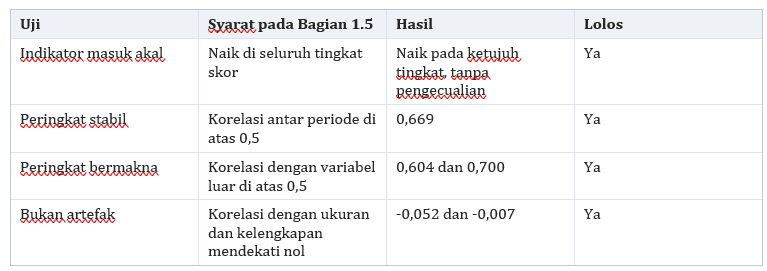

# Temuan

In [25]:
# Ada 170 instansi yang berada di atas norma pasarnya pada dua periode terpisah

M["gigih"] = (M["lo_A"] > 1) & (M["lo_B"] > 1)

M["jenis"] = np.select(
    [M["induk"].str.startswith("KAB. "),
     M["induk"].str.startswith("KOTA "),
     M["induk"].str.startswith("PROV. ")],
    ["Kabupaten", "Kota", "Provinsi"], default="Pusat dan lainnya")

# Temuan 1
kolom = ["induk","jenis","n_A","oe_A","n_B","oe_B","lo_B","hi_B"]
t1 = M[M["gigih"]].sort_values("oe_B", ascending=False).head(25)[kolom]
print(t1.round(2).to_string(index=False))

                   induk     jenis  n_A  oe_A  n_B  oe_B  lo_B  hi_B
      KAB. MAMUJU TENGAH Kabupaten  325  1.66  259  2.04  1.89  2.20
       KAB. PADANG LAWAS Kabupaten  829  1.30  533  2.02  1.92  2.12
      KAB. PULAU MOROTAI Kabupaten  331  1.74  412  2.02  1.91  2.13
               KAB. MUNA Kabupaten 1079  1.82  624  1.94  1.85  2.03
        KOTA TASIKMALAYA      Kota 1003  1.24  635  1.92  1.83  2.01
         KAB. GUNUNG MAS Kabupaten  688  1.32  545  1.89  1.80  1.98
       KAB. NIAS SELATAN Kabupaten  605  1.63  527  1.88  1.78  1.98
             KOTA SORONG      Kota  183  1.59  104  1.88  1.65  2.10
KAB. HULU SUNGAI SELATAN Kabupaten  852  1.22  356  1.84  1.72  1.95
       KAB. KONAWE UTARA Kabupaten  432  1.41  523  1.83  1.74  1.92
              KAB. DEMAK Kabupaten 1086  1.33  673  1.78  1.71  1.85
             KAB. SELUMA Kabupaten  512  1.62  308  1.78  1.68  1.88
          KOTA PALEMBANG      Kota 2597  1.21 1806  1.77  1.72  1.81
      KOTA LUBUK LINGGAU      Kota

skor risiko yang benar-benar terjadi di Kabupaten Mamuju Tengah dua kali lipat dari yang diperkirakan, kalau kontrak-kontraknya diganti dengan kontrak instansi lain pada tahun dan pasar yang sama.

Tindak lanjut: daftar ini adalah urutan prioritas pemeriksaan, bukan daftar tuduhan.

In [26]:
# Risiko terpusat di tingkat Kabupaten, hampir tidak ada di tingkat provinsi

t2 = M.groupby("jenis").agg(instansi=("induk","size"),
                            gigih=("gigih","sum"),
                            median_OE_B=("oe_B","median"))
t2["persen_gigih"] = (100*t2["gigih"]/t2["instansi"]).round(0)
print(t2.round(2).to_string())

                   instansi  gigih  median_OE_B  persen_gigih
jenis                                                        
Kabupaten               371    137         1.03          37.0
Kota                     80     26         0.86          32.0
Provinsi                 34      2         0.75           6.0
Pusat dan lainnya        33      5         0.87          15.0


Tindak lanjut: kalau kapasitas pemeriksaan hanya cukup untuk satu tingkat pemerintahan, tingkat kabupaten yang paling banyak memberi hasil.

In [27]:
# Pendorong risiko berbeda dari satu instansi ke instansi lain, sehingga pemeriksaan tidak boleh seragam

d = df[df["siap"] & df["tahun"].between(2019, 2023)].copy()
d["sel"] = d["tahun"].astype(str) + "-" + d["pasar"]

def oe_komponen(data, kolom):
    tmp = data.assign(ev=(data[kolom] == 100).astype(float))
    sel = tmp.groupby("sel")["ev"].agg(["size","sum"]).rename(columns={"size":"n_c","sum":"o_c"})
    ic  = (tmp.groupby(["induk","sel"])["ev"].agg(["size","sum"])
              .rename(columns={"size":"n_ic","sum":"o_ic"}).reset_index().join(sel, on="sel"))
    sisa = ic["n_c"] - ic["n_ic"]
    ic["e"] = np.where(sisa > 0,
                       ic["n_ic"]*(ic["o_c"]-ic["o_ic"])/sisa.replace(0, np.nan), np.nan)
    g = ic[ic["e"].notna()].groupby("induk").agg(O=("o_ic","sum"), E=("e","sum"))
    return (g["O"]/g["E"]).rename("oe_" + kolom[2:])

prof = pd.concat([oe_komponen(d, k) for k in ["r_satu","r_iklan","r_putus"]], axis=1)
P = M.join(prof, on="induk")
G = P[P["gigih"]]
for c in ["oe_satu","oe_iklan","oe_putus"]:
    n_tinggi = int((G[c] > 1.5).sum())
    print(f"{c:9s} median {G[c].median():.2f} | O/E di atas 1,5 pada {n_tinggi} instansi")
P.to_csv("profil_instansi.csv", index=False)


oe_satu   median 1.76 | O/E di atas 1,5 pada 108 instansi
oe_iklan  median 1.32 | O/E di atas 1,5 pada 67 instansi
oe_putus  median 1.73 | O/E di atas 1,5 pada 96 instansi


Tindak lanjut: surat permintaan keterangan ke Kabupaten Pulau Morotai dan ke Kementerian Pertahanan seharusnya menanyakan hal yang berbeda. Daftar periksa yang seragam akan menghasilkan jawaban yang tidak berguna pada keduanya.

In [28]:
# Selisih pembayaran terhadap norma pasar mencapai Rp 24,8 triliun

v = df[df["harga_wajar"] & df["pasar"].notna() & df["tahun"].between(2013, 2023)]

sel = v.groupby(["tahun","pasar"]).agg(sh=("bid_price_local_currency","sum"),
                                       sp=("tender_estimatedprice_local_currency","sum"))
ic = (v.groupby(["induk","tahun","pasar"])
        .agg(n=("bid_id","size"), ih=("bid_price_local_currency","sum"),
             ip=("tender_estimatedprice_local_currency","sum")).reset_index()
        .join(sel, on=["tahun","pasar"]))

# nilai yang diharapkan: HPS instansi ini dikali efisiensi harga instansi LAIN di sel yang sama
sisa = ic["sp"] - ic["ip"]
ic["harap"] = np.where(sisa > 0, ic["ip"]*(ic["sh"]-ic["ih"])/sisa.replace(0, np.nan), np.nan)

u = (ic[ic["harap"].notna()].groupby("induk")
       .agg(n=("n","sum"), bayar=("ih","sum"), harap=("harap","sum")))
u["gigih"] = u.index.isin(set(M.loc[M["gigih"], "induk"]))

for nama, g in [("170 instansi", u[u["gigih"]]), ("instansi lain", u[~u["gigih"]])]:
    s = g["bayar"].sum() - g["harap"].sum()
    print(f"{nama:14s} {len(g):5d} instansi | kontrak {int(g['n'].sum()):>9,}"
          f" | dibayar Rp {g['bayar'].sum()/1e12:7.1f} T"
          f" | diperkirakan Rp {g['harap'].sum()/1e12:7.1f} T"
          f" | selisih Rp {s/1e12:+6.1f} T ({100*s/g['harap'].sum():+.2f}%)")
u.reset_index().to_csv("selisih_rupiah.csv", index=False)


170 instansi     170 instansi | kontrak   227,868 | dibayar Rp   446.6 T | diperkirakan Rp   421.8 T | selisih Rp  +24.8 T (+5.88%)
instansi lain   2701 instansi | kontrak   649,517 | dibayar Rp  1643.2 T | diperkirakan Rp  1673.6 T | selisih Rp  -30.4 T (-1.82%)


pada kontrak dengan nilai setara di pasar dan tahun yang sama, kelompok 170 instansi itu membayar 5,88 persen lebih tinggi daripada perkiraan, sedangkan instansi lain membayar 1,82 persen lebih rendah.

In [29]:
# Selisih rupiah terbesar justru ada di instansi pusat, bukan di instansi dengan O/E tertinggi

u = pd.read_csv("selisih_rupiah.csv")

ket = df.groupby("induk").agg(kontrak=("bid_id","size"),
                              med_rasio=("rasio_hps","median"))
G = (M[M["gigih"]]
       .merge(u[["induk","bayar","harap"]], on="induk", how="left")
       .join(ket, on="induk"))
G["selisih"] = G["bayar"] - G["harap"]

t5 = G.sort_values("selisih", ascending=False).head(10)[
        ["induk","kontrak","oe_A","oe_B","bayar","selisih","med_rasio"]].copy()
t5["bayar"]   = (t5["bayar"]/1e12).round(1)
t5["selisih"] = (t5["selisih"]/1e9).round(0)
t5.columns = ["instansi","kontrak","O/E_A","O/E_B","dibayar_Rp_T",
              "selisih_Rp_miliar","med_rasio"]
print(t5.round(3).to_string(index=False))

                                  instansi  kontrak  O/E_A  O/E_B  dibayar_Rp_T  selisih_Rp_miliar  med_rasio
      KEPOLISIAN NEGARA REPUBLIK INDONESIA    24797  1.340  1.612         142.7            10252.0      0.991
                    KEMENTERIAN PERTAHANAN    14210  1.222  1.250          19.2             1281.0      0.997
KEMENTERIAN HUKUM DAN HAK ASASI MANUSIA RI     4414  1.210  1.358          14.0              759.0      0.980
                                KAB. PASER     3560  1.557  1.630           6.8              403.0      0.993
                       KAB. MUSI BANYUASIN     7537  1.082  1.139           6.0              316.0      0.990
                              PROV. MALUKU     5164  1.145  1.456           4.7              239.0      0.983
                           KAB. MUSI RAWAS     3776  1.030  1.618           3.9              237.0      0.994
                        PROV. MALUKU UTARA     4132  1.301  1.358           6.2              232.0      0.974
          

Tindak lanjut: kalau yang dikejar dampak anggaran yang besar, pemeriksaan diarahkan ke daftar rupiah. Kalau tujuannya memperbaiki tata kelola daerah, pemeriksaan diarahkan ke daftar O/E.

In [30]:
# Pekerjaan konstruksi adalah pasar yang paling terpengaruh, dan bebannya Rp 136,5 triliun

dg  = d[d["induk"].isin(set(M.loc[M["gigih"], "induk"]))]
nas = d.groupby("pasar")["cri"].mean().rename("cri_nasional")
sg  = (dg.groupby("pasar").agg(kontrak=("cri","size"), cri_gigih=("cri","mean"),
                               nilai=("bid_price_local_currency","sum")).join(nas))
sg = sg[sg["kontrak"] >= 2000].sort_values("cri_gigih", ascending=False)
sg["selisih"] = (sg["cri_gigih"] - sg["cri_nasional"]).round(1)
sg["nilai_Rp_T"] = (sg["nilai"]/1e12).round(1)
print(sg[["kontrak","cri_gigih","cri_nasional","selisih","nilai_Rp_T"]].round(1).to_string())


       kontrak  cri_gigih  cri_nasional  selisih  nilai_Rp_T
pasar                                                       
39        2648       64.5          52.0     12.5         4.1
15        2798       62.5          48.9     13.5         8.2
34        3383       62.4          45.6     16.8         9.6
50        2394       62.3          53.6      8.7         4.6
85        3417       61.5          41.5     20.0         2.4
45       65639       56.0          38.5     17.4       136.5
30        2521       49.4          36.6     12.8         7.4
71        2682       22.9          14.3      8.6         8.4


Tindak lanjut: pemeriksaan di 170 instansi dimulai dari paket konstruksi.

In [31]:
# Pola harga menempel HPS jauh lebih sering di 170 instansi itu

pen = pd.read_parquet("analisis_siap.parquet", columns=["bidder_masterid"])
df["bidder_masterid"] = pen["bidder_masterid"].reindex(df.index)
gg = set(M.loc[M["gigih"], "induk"])
dh = df[df["harga_wajar"] & df["tahun"].between(2019, 2023)]

def pasangan(data):
    p = (data.groupby(["induk","bidder_masterid"])
             .agg(kontrak=("bid_id","size"), nilai=("bid_price_local_currency","sum"),
                  med=("rasio_hps","median")).reset_index())
    return p[p["kontrak"] >= 15]

pg = pasangan(dh[dh["induk"].isin(gg)])
pl = pasangan(dh[~dh["induk"].isin(gg)])
for nama, p in [("di 170 instansi", pg), ("di instansi lain", pl)]:
    print(f"{nama:18s} pasangan {len(p):4d} | menempel HPS {int((p['med']>=0.99).sum()):4d}"
          f" ({100*(p['med']>=0.99).mean():.1f}%)")
print("nilai pasangan menempel HPS di 170 instansi: Rp",
      round(pg.loc[pg['med']>=0.99, 'nilai'].sum()/1e12, 1), "triliun")



di 170 instansi    pasangan  916 | menempel HPS  561 (61.2%)
di instansi lain   pasangan 1023 | menempel HPS  137 (13.4%)
nilai pasangan menempel HPS di 170 instansi: Rp 53.6 triliun


Tindak lanjut: ini adalah butir pemeriksaan yang paling konkret. Untuk setiap instansi prioritas, ambil daftar pasangan penyedia dengan median rasio di atas 0,99 dan periksa berkas penetapan HPS pada paket-paket tersebut. Nama penyedia tidak dipublikasikan, hanya dipakai dalam berkas kerja internal.

In [32]:
# Ada instansi yang membaik dan ada yang memburuk, dan keduanya penting

membaik  = M[(M["lo_A"] > 1) & (M["hi_B"] < 1)]
memburuk = M[(M["hi_A"] < 1) & (M["lo_B"] > 1)]

print("membaik :", len(membaik))
print(membaik.sort_values("oe_A", ascending=False)
             .head(5)[["induk","n_A","oe_A","n_B","oe_B"]].round(2).to_string(index=False))
print("memburuk:", len(memburuk))
print(memburuk.sort_values("oe_B", ascending=False)
              .head(5)[["induk","n_A","oe_A","n_B","oe_B"]].round(2).to_string(index=False))

membaik : 52
             induk  n_A  oe_A  n_B  oe_B
       KOTA BLITAR  474  1.73  199  0.80
   KAB. BENGKAYANG  607  1.65  203  0.49
KAB. PAKPAK BHARAT  365  1.55  206  0.90
  KOTA LHOKSEUMAWE  281  1.50  264  0.82
     KAB. POHUWATO  655  1.48  230  0.80
memburuk: 28
                       induk  n_A  oe_A  n_B  oe_B
KAB. OGAN KOMERING ULU TIMUR  399  0.70 1712  1.72
                KOTA TOMOHON  306  0.88  286  1.64
            KAB. MURUNG RAYA  889  0.95  255  1.49
                   KOTA TUAL  402  0.83  274  1.41
             KOTA PRABUMULIH  847  0.48  485  1.29


Tindak lanjut: kelompok 28 instansi diperiksa lebih dulu daripada instansi yang sudah lama tinggi, karena penurunan tata kelola yang baru terjadi lebih mudah dikoreksi.

# Use Case: Customer Segmentation pada Instansi Pembeli

In [33]:
# Dalam data pengadaan, instansi adalah pembeli (buyer). Segmen disusun dari
# perilaku pembeliannya pada dua periode, yaitu posisi O/E terhadap norma pasar.

S = P.merge(u[["induk", "bayar", "harap"]], on="induk", how="left")
S["segmen"] = np.select(
    [S["gigih"],
     (S["hi_A"] < 1) & (S["lo_B"] > 1),
     (S["lo_A"] > 1) & (S["hi_B"] < 1)],
    ["Di atas norma dua periode", "Memburuk", "Membaik"], default="Lainnya")

URUT = ["Di atas norma dua periode", "Memburuk", "Membaik", "Lainnya"]
seg = (S.groupby("segmen")
        .agg(instansi=("induk", "size"),
             kabupaten=("jenis", lambda s: int((s == "Kabupaten").sum())),
             OE_2013_2018=("oe_A", "median"),
             OE_2019_2023=("oe_B", "median"),
             sepi_penawar=("oe_satu", "median"),
             iklan_pendek=("oe_iklan", "median"),
             putusan=("oe_putus", "median"),
             bayar=("bayar", "sum"), harap=("harap", "sum"))
        .reindex(URUT))
seg["persen_instansi"] = (100*seg["instansi"]/seg["instansi"].sum()).round(1)
seg["harga_vs_perkiraan"] = (100*(seg["bayar"] - seg["harap"])/seg["harap"]).round(2)
print(seg[["instansi", "persen_instansi", "kabupaten", "OE_2013_2018", "OE_2019_2023",
           "sepi_penawar", "iklan_pendek", "putusan", "harga_vs_perkiraan"]]
        .round(2).to_string())


                           instansi  persen_instansi  kabupaten  OE_2013_2018  OE_2019_2023  sepi_penawar  iklan_pendek  putusan  harga_vs_perkiraan
segmen                                                                                                                                              
Di atas norma dua periode       170             32.8        137          1.34          1.38          1.76          1.32     1.73                5.88
Memburuk                         28              5.4         23          0.82          1.17          1.43          1.10     0.94                3.28
Membaik                          52             10.0         30          1.16          0.77          0.45          0.81     0.32                1.15
Lainnya                         268             51.7        181          0.86          0.80          0.41          0.67     0.42               -3.30


Empat segmen instansi pembeli, empat perlakuan:
1. Di atas norma dua periode (170): prioritas pemeriksaan, mulai dari paket konstruksi dan pasangan penyedia yang harganya menempel HPS.
2. Memburuk (28): peringatan dini, diperiksa lebih dulu karena penurunan yang baru terjadi lebih mudah dikoreksi.
3. Membaik (52): dipelajari sebagai contoh praktik baik bagi instansi sejenis.
4. Lainnya (268): pemantauan rutin tahunan.

Bukti bahwa segmen ini bermakna: segmen disusun hanya dari skor proses, tetapi harga ikut berurutan dari +5,88 persen sampai -3,30 persen. Harga tidak dipakai menyusun segmen.


In [34]:
# Dua dugaan yang diuji dan tidak terbukti
# 1. Instansi berisiko memusatkan kontrak pada sedikit penyedia
# 2. Pasangan pembeli dan penyedia yang berulang menandakan risiko lebih tinggi


pen = pd.read_parquet("analisis_siap.parquet", columns=["bidder_masterid"])
df["bidder_masterid"] = pen["bidder_masterid"].reindex(df.index)

gg = set(M.loc[M["gigih"], "induk"])
b  = df[df["tahun"].between(2019, 2023) & df["bidder_masterid"].notna()]

def pemusatan(data):
    p   = data.groupby(["induk","bidder_masterid"]).size().rename("n").reset_index()
    tot = p.groupby("induk")["n"].agg(total="sum", n_penyedia="size")
    top = p.groupby("induk")["n"].max().rename("terbesar")
    r   = tot.join(top)
    r   = r[r["total"] >= 100]
    return (round(100*(r["terbesar"]/r["total"]).median(), 1),
            int(round(r["n_penyedia"].median())), len(r))

a = pemusatan(b[b["induk"].isin(gg)])
c = pemusatan(b[~b["induk"].isin(gg)])
print(f"di 170 instansi  : pangsa penyedia terbesar {a[0]} persen | median {a[1]} penyedia")
print(f"di instansi lain : pangsa penyedia terbesar {c[0]} persen | median {c[1]} penyedia")

di 170 instansi  : pangsa penyedia terbesar 2.8 persen | median 196 penyedia
di instansi lain : pangsa penyedia terbesar 2.6 persen | median 214 penyedia


# Ekspor File untuk Dashboard

In [35]:
import pandas as pd, numpy as np

KOL = ["bid_id","tender_id","lot_id","induk","buyer_name","bidder_masterid","bidder_name",
       "tahun","pasar","cpv_code","tender_supplytype","tender_proceduretype",
       "cri","r_satu","r_iklan","r_putus","satu_penawar","n_baris",
       "rasio_hps","harga_wajar","bid_price_local_currency",
       "tender_estimatedprice_local_currency","buyer_county_here","buyer_city_here","siap"]
df = pd.read_parquet("analisis_siap.parquet", columns=KOL)
M  = pd.read_csv("oe_instansi.csv")
P  = pd.read_csv("profil_instansi.csv")
S  = pd.read_csv("selisih_rupiah.csv")

# 1. tabel kontrak
k = df[df["tahun"].between(2013, 2023)].copy()
k = k.rename(columns={"bid_price_local_currency":"harga",
                      "tender_estimatedprice_local_currency":"hps",
                      "buyer_county_here":"provinsi", "buyer_city_here":"kota",
                      "tender_supplytype":"jenis_pengadaan", "tender_proceduretype":"prosedur"})
k["periode"] = np.where(k["tahun"] <= 2018, "2013-2018", "2019-2023")

# penting: kolom bilangan bulat harus bertipe Int64, bukan float.
# kalau tidak, nilainya tertulis "2020.0" di CSV dan PostgreSQL menolaknya.
for c in ["tahun","satu_penawar","n_baris"]:
    k[c] = pd.to_numeric(k[c], errors="coerce").round().astype("Int64")

kolom_kontrak = ["bid_id","tender_id","lot_id","induk","bidder_masterid","bidder_name",
                 "tahun","periode","pasar","jenis_pengadaan","prosedur","provinsi","kota",
                 "n_baris","satu_penawar","r_satu","r_iklan","r_putus","cri",
                 "harga","hps","rasio_hps","harga_wajar","siap"]
k[kolom_kontrak].to_csv("dasbor_kontrak.csv", index=False)

# 2. tabel instansi
ext = df.groupby("induk").agg(kontrak=("bid_id","size"),
        penyedia=("bidder_masterid","nunique"),
        nilai=("bid_price_local_currency","sum"),
        med_rasio=("rasio_hps","median"))
prov = (df.dropna(subset=["buyer_county_here"])
          .groupby(["induk","buyer_county_here"]).size().reset_index(name="n")
          .sort_values("n", ascending=False).drop_duplicates("induk")
          .set_index("induk")["buyer_county_here"].rename("provinsi"))

ins = (M.merge(P[["induk","oe_satu","oe_iklan","oe_putus"]], on="induk", how="left")
         .merge(S[["induk","bayar","harap"]], on="induk", how="left")
         .join(ext, on="induk").join(prov, on="induk"))
ins["selisih_rupiah"] = ins["bayar"] - ins["harap"]
ins["jenis"] = np.select([ins["induk"].str.startswith("KAB. "),
                          ins["induk"].str.startswith("KOTA "),
                          ins["induk"].str.startswith("PROV. ")],
                         ["Kabupaten","Kota","Provinsi"], "Pusat dan lainnya")
ins["status"] = np.select(
    [ins["gigih"], (ins["lo_A"]>1)&(ins["hi_B"]<1), (ins["hi_A"]<1)&(ins["lo_B"]>1)],
    ["Di atas norma dua periode","Membaik","Memburuk"], "Lainnya")
for c in ["n_A","n_B","kontrak","penyedia"]:
    ins[c] = pd.to_numeric(ins[c], errors="coerce").round().astype("Int64")
ins.to_csv("dasbor_instansi.csv", index=False)

# 3. tabel pasangan instansi dan penyedia
g = set(M.loc[M["gigih"], "induk"])
p = (df[df["harga_wajar"] & df["tahun"].between(2019, 2023)]
       .groupby(["induk","bidder_masterid"])
       .agg(nama_penyedia=("bidder_name","max"), kontrak=("bid_id","size"),
            nilai=("bid_price_local_currency","sum"),
            med_rasio=("rasio_hps","median"), cri_rata=("cri","mean")).reset_index())
p = p[p["kontrak"] >= 15]
p["instansi_prioritas"] = p["induk"].isin(g)
p["menempel_hps"] = p["med_rasio"] >= 0.99
p["kontrak"] = p["kontrak"].astype("Int64")
p.to_csv("dasbor_penyedia.csv", index=False)
